# Data and Phase 1 baseline

Eight subjects: two dogs, two cats, four objects. The pretrained model knows the word dog, but not our dog. Phase 1 has no fine-tuning. We prompt with the class only (`a dog on the beach`) and the dogs that come back are different dogs.

The token is `zwx`. After fine-tuning the prompt is `a zwx dog on the beach`. Each subject gets its own model, so they can share that token.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from configs.subjects import (
    DOG_FIGURE_PROMPT_INDICES,
    MODEL_ID,
    SUBJECTS,
    TOKEN,
    class_prompt,
    instance_prompt,
    prompt_rows,
    subject_by_name,
)

REFERENCES = ROOT / "data" / "references"
REFERENCES_512 = ROOT / "data" / "references_512"
PHASE1 = ROOT / "phase1" / "outputs"

print("model:", MODEL_ID)
print("token:", TOKEN)
print("subjects:", len(SUBJECTS))


model: sd-legacy/stable-diffusion-v1-5
token: zwx
subjects: 8


## Reference photos

One folder per subject. These are the photos we train on. `dog` and `dog2` are both dogs, but not the same dog. Same for the two cats.


dog                  class=dog          live   photos=5
dog2                 class=dog          live   photos=6
cat                  class=cat          live   photos=5
cat2                 class=cat          live   photos=5
backpack             class=backpack     object photos=6
clock                class=clock        object photos=6
teapot               class=teapot       object photos=5
colorful_sneaker     class=sneaker      object photos=5


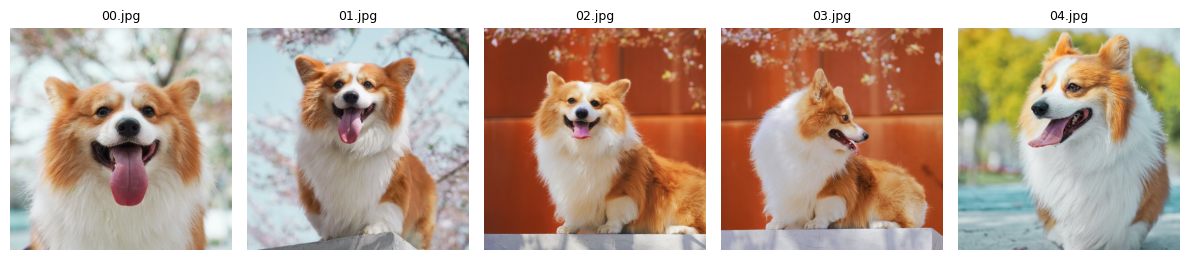

dog dog 5 photos


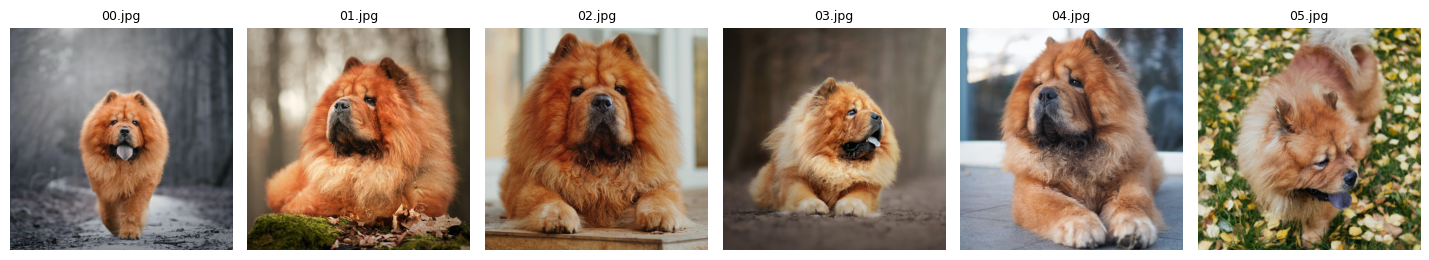

dog2 dog 6 photos


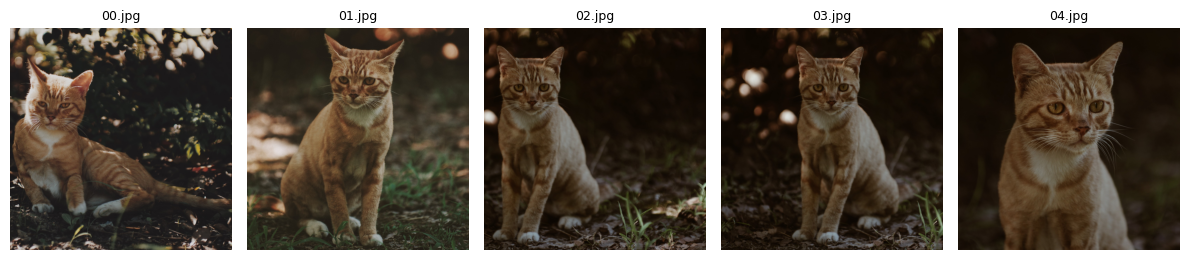

cat cat 5 photos


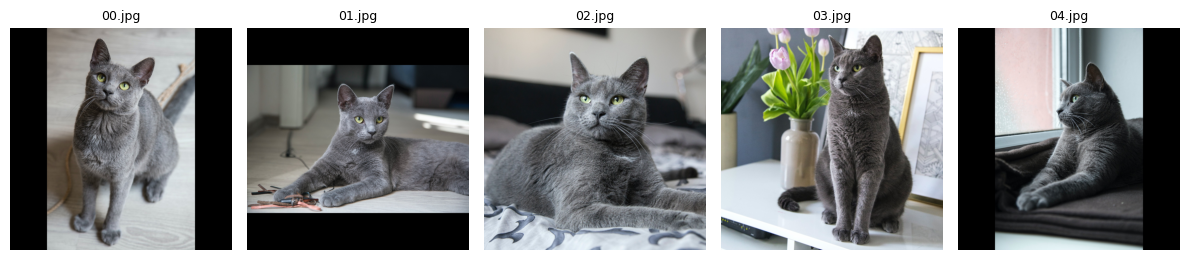

cat2 cat 5 photos


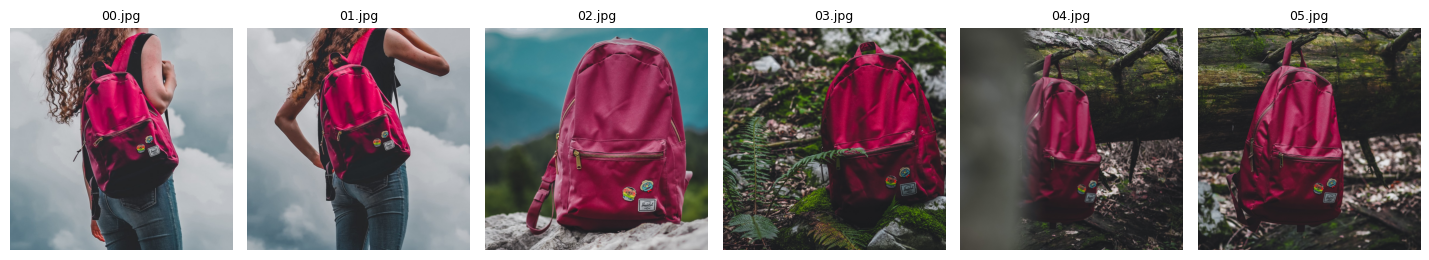

backpack backpack 6 photos


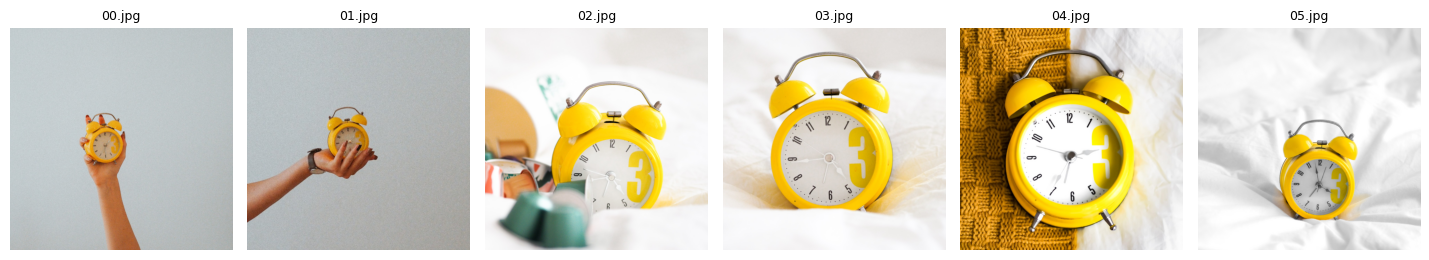

clock clock 6 photos


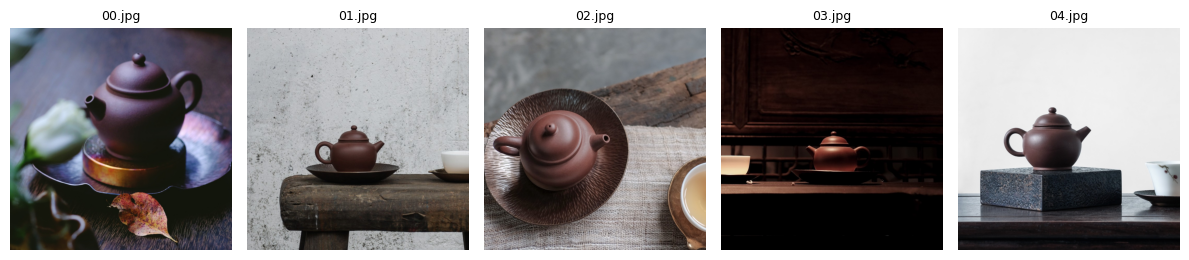

teapot teapot 5 photos


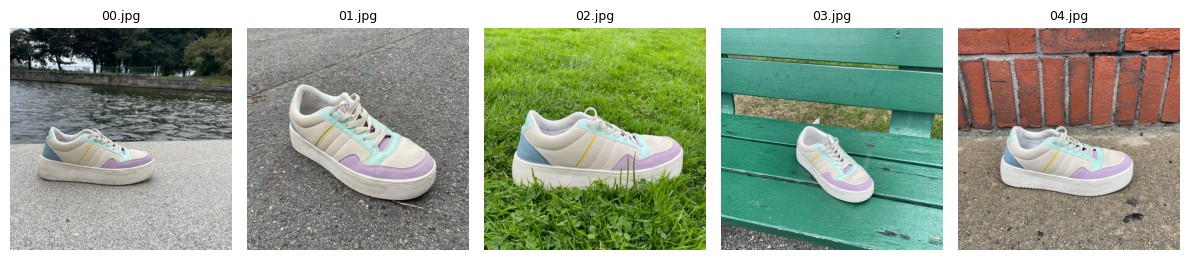

colorful_sneaker sneaker 5 photos


In [2]:
rows = []
for subject in SUBJECTS:
    paths = sorted((REFERENCES / subject["name"]).glob("*"))
    rows.append(
        f"{subject['name']:20} class={subject['class_name']:12} {subject['kind']:6} photos={len(paths)}"
    )
print("\n".join(rows))


def show_grid(items, ncols, figsize):
    nrows = (len(items) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = list(axes.ravel()) if hasattr(axes, "ravel") else [axes]
    for ax in axes:
        ax.axis("off")
    for ax, (image, title) in zip(axes, items):
        ax.imshow(image)
        ax.axis("off")
        if title:
            ax.set_title(title, fontsize=9)
    fig.tight_layout()
    plt.show()


for subject in SUBJECTS:
    paths = sorted(
        p
        for p in (REFERENCES / subject["name"]).iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    show_grid(
        [(Image.open(path), path.name) for path in paths],
        ncols=len(paths),
        figsize=(2.4 * len(paths), 2.8),
    )
    print(subject["name"], subject["class_name"], len(paths), "photos")


## 512×512 center crop

Training wants 512x512. We resize the short side to 512 and center-crop. These photos are already square, so this mostly just resizes them. Originals stay in `data/references`. Training uses `data/references_512`.


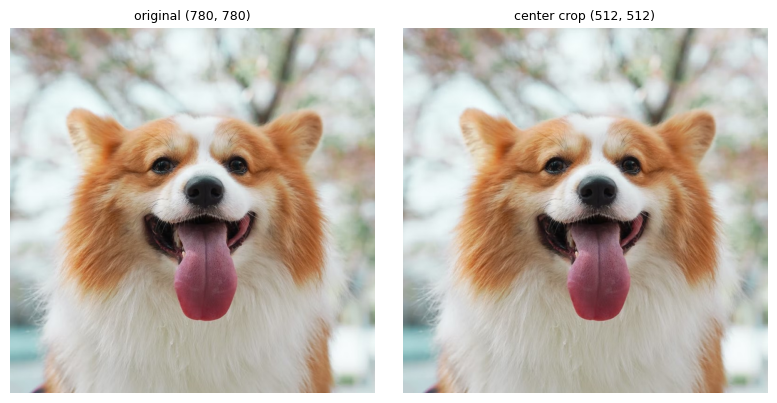

In [3]:
original = Image.open(sorted((REFERENCES / "dog").glob("*.jpg"))[0])
cropped = Image.open(sorted((REFERENCES_512 / "dog").glob("*.png"))[0])
show_grid(
    [(original, f"original {original.size}"), (cropped, f"center crop {cropped.size}")],
    ncols=2,
    figsize=(8, 4),
)


## Prompts

The instance prompt goes with the real photos. The class prompt goes with the class images. The 25 prompts are from the DreamBooth dataset. Live subjects get outfits. Objects get new places.


In [4]:
dog = subject_by_name("dog")
backpack = subject_by_name("backpack")
print("instance prompt:", instance_prompt(dog))
print("class prompt:   ", class_prompt(dog))
print()
print(f"{'phase 1 (pretrained)':42} phase 2 (after fine-tune)")
for row in prompt_rows(dog):
    print(f"{row['phase1']:42} {row['phase2']}")
print()
print("object example, backpack")
for row in prompt_rows(backpack)[:3]:
    print(f"{row['phase1']:42} {row['phase2']}")
print("...")
print("evaluation prompts per subject:", len(prompt_rows(dog)))


instance prompt: a photo of zwx dog
class prompt:    a photo of a dog

phase 1 (pretrained)                       phase 2 (after fine-tune)
a dog in the jungle                        a zwx dog in the jungle
a dog in the snow                          a zwx dog in the snow
a dog on the beach                         a zwx dog on the beach
a dog on a cobblestone street              a zwx dog on a cobblestone street
a dog on top of pink fabric                a zwx dog on top of pink fabric
a dog on top of a wooden floor             a zwx dog on top of a wooden floor
a dog with a city in the background        a zwx dog with a city in the background
a dog with a mountain in the background    a zwx dog with a mountain in the background
a dog with a blue house in the background  a zwx dog with a blue house in the background
a dog on top of a purple rug in a forest   a zwx dog on top of a purple rug in a forest
a dog wearing a red hat                    a zwx dog wearing a red hat
a dog wearing 

## Phase 1 identity failure

Top row is our dog after the 512 crop. Each row under it is four images from the pretrained model. It never saw these five photos, so those dogs are not our dog.


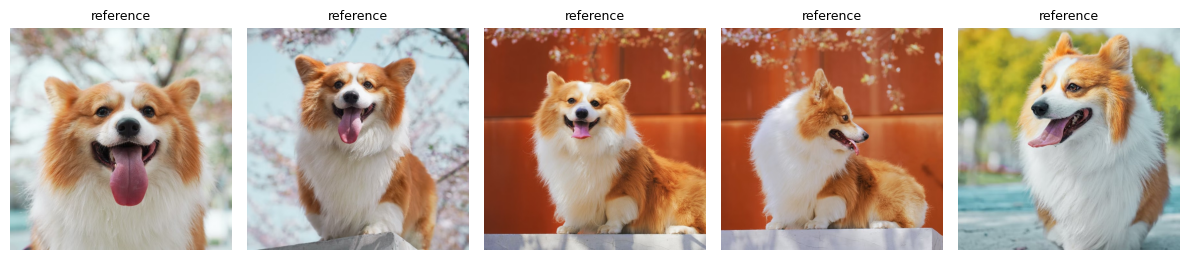

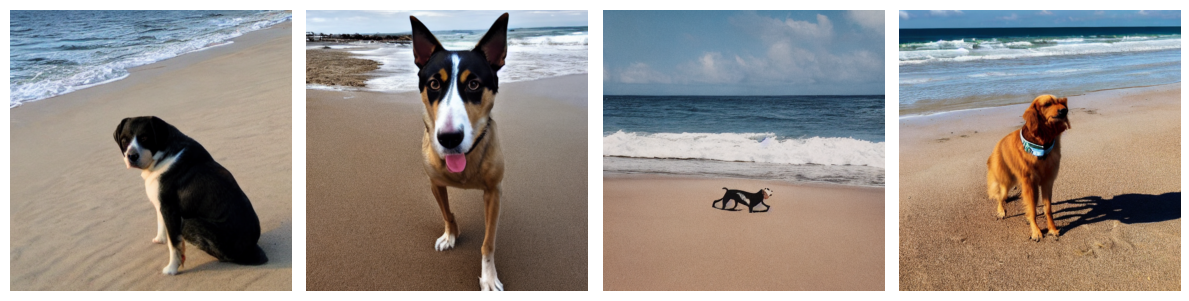

a dog on the beach


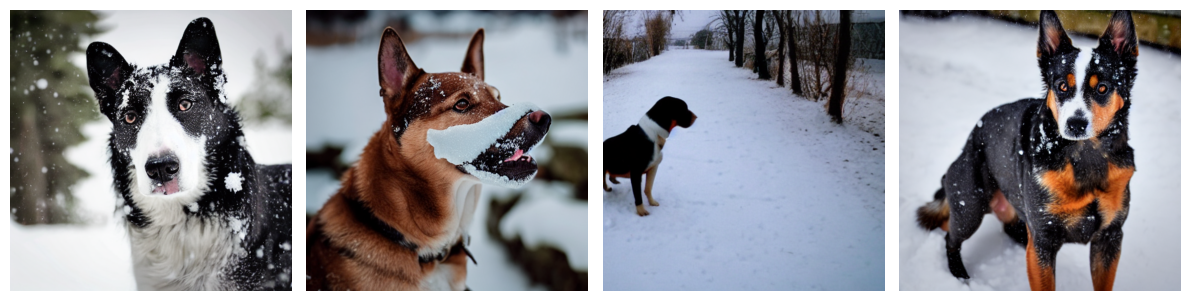

a dog in the snow


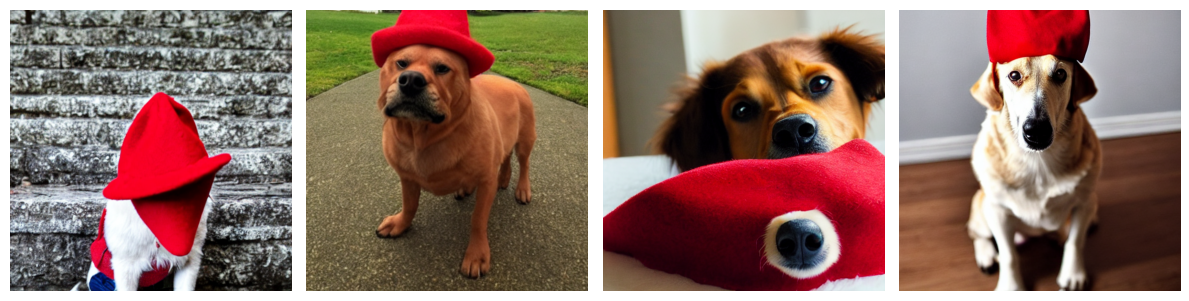

a dog wearing a red hat


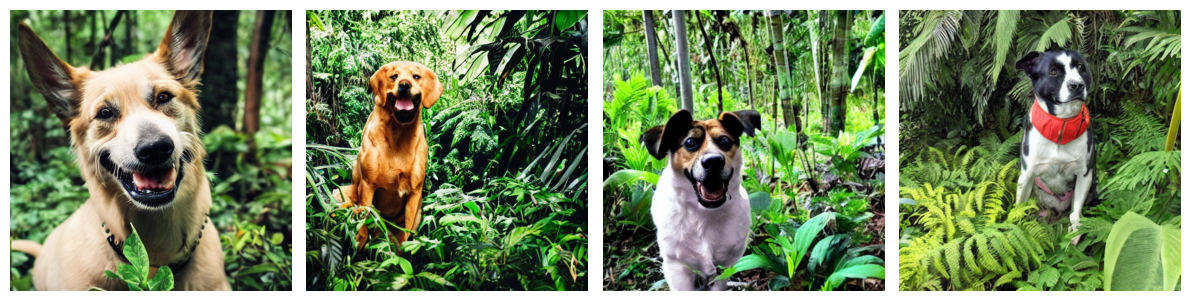

a dog in the jungle


In [5]:
dog_refs = sorted((REFERENCES_512 / "dog").glob("*.png"))
show_grid([(Image.open(path), "reference") for path in dog_refs], ncols=5, figsize=(12, 2.8))

dog = subject_by_name("dog")
rows = prompt_rows(dog)
for index in DOG_FIGURE_PROMPT_INDICES:
    prompt = rows[index]["phase1"]
    paths = [PHASE1 / "dog" / f"p{index:02d}_s{sample}.png" for sample in range(4)]
    missing = [path.name for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(f"Missing Phase 1 images for {prompt}: {missing}")
    show_grid([(Image.open(path), "") for path in paths], ncols=4, figsize=(12, 3.2))
    print(prompt)
